# **MODULE 35 — AUDIO REPRESENTATIONS & FEATURE ENGINEERING FOR MACHINE LEARNING**

## **35.1 — ML-Specific Audio Preparation**



Must Know

Practical Lab 35A



### **1. Why do we need ML-specific audio preparation?**

Imagine collecting 1,000 speech recordings for emotion classification.

Your dataset might contain:

- Recording A: 3 seconds, 16,000 Hz, stereo.
- Recording B: 5 seconds, 22,050 Hz, mono.
- Recording C: 8 seconds, 44,100 Hz, stereo.

These recordings have different:

- Sampling rates.
- Number of channels.
- Durations.
- Amplitude ranges.

But your ML model needs a consistent input representation.

For example, a CNN operating on fixed-size spectrograms may expect every recording to produce an input with the same dimensions.

**Our objective:** Convert different recordings into a consistent representation without destroying useful emotional information.

### **2. Consistent sample-rate handling**

Must Know

The sample rate tells us how many audio samples are captured per second.

For example:

| Sample rate | Samples in 1 second |
| ----------- | ------------------- |
| 16,000 Hz   | 16,000              |
| 22,050 Hz   | 22,050              |
| 44,100 Hz   | 44,100              |

Suppose your SER model uses 16,000 Hz audio.

But an input recording has a sample rate of 44,100 Hz.

We need to convert it to 16,000 Hz using **resampling**.

![Yufan's Blog - TensorFlow Speech Recognition Competition Wav Preprocessing](https://images.openai.com/static-rsc-4/ZZpFPaispQ3SrOn8AlIjClJONZlsaONsEkeb5gJ3lxnW4zmhU8fJyR_itiisjGd6tqxVDd4kwU4l1TLnwzbvrOMD-KcwdMKuEFHnXFGUW_BMeXWz8bxS1iP5scEWd9EHzc7wp3qyCcXNkvQEQ1x-2TEapPUHamj_KNS1j4RBEF8?purpose=inline)

[alphafan.github.io](https://alphafan.github.io/posts/tf_sr_wav_pp.html?utm_source=chatgpt.com)

#### **Important: Changing the sample-rate label is NOT resampling.**

Consider:

```
audio, sr = librosa.load("sample.wav", sr=None)
```

Here, `sr=None` preserves the original sample rate.

Incorrect:

```
sr = 16000
```

This only changes the variable. It does not change the waveform's samples.

Correct:

```
audio_16k = librosa.resample(    audio,    orig_sr=sr,    target_sr=16000)
```

Now the waveform has actually been resampled.

**Why does this matter?**

If you simply relabel a 44,100 Hz waveform as 16,000 Hz, the playback speed, duration, and pitch interpretation will be wrong.

#### **Check your understanding**

If a 4-second recording is sampled at 44,100 Hz:

\\[ N = 4 \times 44100 = 176400 \\]

After resampling to 16,000 Hz:

\\[ N\_{\text{new}} = 4 \times 16000 = 64000 \\]

The duration remains approximately 4 seconds, but the number of samples changes.

### **3. Mono conversion and channel selection**

Must Know

Audio can contain one or multiple channels.

![Convert a mono or stereo track - Learning Audacity](https://images.openai.com/static-rsc-4/OMM6G9D8zzqKsTNEHPHjNzrXbS65t1VhAdPXwlvnsaWfzXSi3jvHlf47-t1KPEYEb5KPI_R3MKW8QX4e5NSJRnxt06ygFOnQEvOkmSlgeBMMTfy9EjU9pJldYws17mfYdEcca60uTDb5Y8IHDMwQXFpk0vfYKhjJXZyOnNEuwtE?purpose=inline)

**Mono**

One audio channel.

![Implementation of Sound Direction Detection and Mixed Source Separation in Embedded Systems](https://images.openai.com/static-rsc-4/3lsq2Hy0T-CU7Wiz_GfCuYJ9BfyLxCJrX_q1cc_IfvFtuPPS3wWIeDf69kpXrO40jpLP5WRalkL745TzWNl2Nr6yhc7moBOawAMKmabeLSSCL7FiMr2jhtm9fT4RNfSRy_ZsC8ZmkN5Zoym_2Xu-XVBMvWKA-_95I3S4_JGavzo?purpose=inline)

**Stereo**

Two audio channels: left and right.

For ordinary single-speaker SER, mono audio is often sufficient.

A stereo recording can be converted into mono by averaging its channels:

\\[ x\_{\text{mono}}[n] = \frac{x_L[n]+x_R[n]}{2} \\]

Python:

```
import soundfile as sfimport numpy as npaudio, sr = sf.read("sample.wav")if audio.ndim == 2:    audio = np.mean(audio, axis=1)
```

**But be careful!**

Averaging is not always ideal.

For example:

- One microphone may capture the speaker clearly.
- Another may capture background noise.
- Two channels may have phase differences that cause partial cancellation.

In those cases, selecting the cleaner channel may be better than averaging.

### **4. Amplitude normalization**

Must Know

Different recordings may have different recording volumes.

For example:

- Recording A: maximum amplitude = 0.2
- Recording B: maximum amplitude = 0.9

We can normalize peak amplitude.

\\[ x\_{\text{normalized}} = \frac{x}{\max(|x|)} \\]

Python:

```
peak = np.max(np.abs(audio))if peak > 0:    audio = audio / peak
```

This scales the waveform so that its maximum absolute amplitude becomes 1.

![How To Make Your Vocals Twice As Good! Part 1](https://images.openai.com/static-rsc-4/MQqzy4y5OH3_2j3TyWiHrp5Cioi-B7DPDMXYuKPS5LlzdGkzQLHuXlYRUbIJmE0D09AU0cDyX734dwjx2D2J7JcmGa2DG28ty8_AHSkctDdcPCRprnFmNm6Ea5MDAGWUMtL5vGiOTdTAWTMEp0HcYu8YduIFHlbj_jthv8uXfpA?purpose=inline)

[soundonsound.com](https://www.soundonsound.com/techniques/how-make-your-vocals-twice-good-part-1?utm_source=chatgpt.com)

#### **Important limitation for SER**

Peak normalization removes absolute loudness differences.

But loudness can carry emotional information.

For example:

- Anger may involve higher vocal intensity.
- Sadness may involve lower vocal intensity.
- Excitement may involve louder speech.

Therefore, don't automatically normalize every recording without considering your task.

**Our recommendation:** Preserve the original waveform and make normalization an optional preprocessing operation. Record whether it was applied.

### **5. Trimming and padding recordings**

Must Know

ML models often require consistent input lengths.

Suppose your target duration is 4 seconds.

| Recording | Original duration | Action    |
| --------- | ----------------- | --------- |
| A         | 2 seconds         | Padding   |
| B         | 4 seconds         | No change |
| C         | 7 seconds         | Trimming  |

![Preparing data - MATLAB & Simulink](https://images.openai.com/static-rsc-4/rfQvLznxvwCEeqjOtpnr84FqD9B1w-Ha19DPlbqN3NyYk1qGmpkwowBTTRnIr_RIkIcuA59LOocvHzwfdeUz8Rza_ICTaDtNosUgDiSHVRAGqXfUD44s8kqfLpvCFIoG1fN2vfl1w1LXQo0d9ZaG4InupUhipxagY9LJtqCVno0?purpose=inline)

[mathworks.com](https://www.mathworks.com/campaigns/pocket-guides/practical-guide-to-deep-learning/preparing-data.html?utm_source=chatgpt.com)

#### **Padding**

Padding adds samples to shorter recordings.

For example, if the waveform contains 32,000 samples at 16 kHz, it represents 2 seconds.

To reach 4 seconds:

\\[ N\_{\text{target}} = 4 \times 16000 = 64000 \\]

We need:

\\[ 64000-32000=32000 \\]

additional samples.

```
target_samples = 64000audio = np.pad(    audio,    (0, target_samples - len(audio)))
```

This adds zeros at the end.

#### **Trimming**

Trimming removes samples from longer recordings.

```
audio = audio[:target_samples]
```

This keeps the first four seconds.

#### **Important SER consideration**

Trimming from the beginning can remove important emotional content if the emotion occurs later.

Similarly, padding creates artificial silence that can affect feature extraction.

For our SER project, we'll initially use:

- Zero-padding for shorter recordings.
- A defined cropping strategy for longer recordings.
- Original duration and crop information in metadata.

Later, we'll compare fixed-length inputs against variable-length inputs.

### **6. Fixed-length versus variable-length inputs**

Must Know

There are two common strategies.

| Fixed-length                       | Variable-length                         |
| ---------------------------------- | --------------------------------------- |
| All recordings have equal duration | Recordings retain original duration     |
| Easier batching                    | Requires flexible batching              |
| May discard or add audio           | Preserves more original information     |
| Useful for standard CNN pipelines  | Useful for sequence models with masking |

For example:

![Dynamic Batching: What is it and why it is necessary sometimes — SpeechBrain 0.5.0 documentation](https://images.openai.com/static-rsc-4/NO5-WXZJNV1ZCh-UcY10VApEAqbKC3NKRrccNxmk_gxnZAgB5KTh2rGLAjrcGGwWU0foGB2t9cFhWm8d3YR2oGQVnZAM9VGh9y7yEWxsOwNPe_iy1RIesfZi1A_JUGHjXKDXqE-J5Jb4EC-pWjg1k3TzdESo-jgGBL4tCHlRYco?purpose=inline)

[speechbrain.readthedocs.io](https://speechbrain.readthedocs.io/en/stable/tutorials/advanced/dynamic-batching.html?utm_source=chatgpt.com)

For our first SER baseline, we'll use fixed-length audio.

Later, we can explore variable-length inputs with padding masks or sequence-aware architectures.

### **7. Audio segmentation and utterance boundaries**

Must Know

An utterance is a continuous segment of speech that conveys a meaningful expression.

Consider:

> "I can't believe you did that!"

This might be one utterance.

But a complete recording could contain several utterances separated by pauses.

Audio segmentation divides recordings into smaller meaningful portions.

![Pipeline Explained - SpeechLine](https://images.openai.com/static-rsc-4/vCudOOv0Tmki70lda4gmQkyauHdvnRRORey-V16weoXSDE56SDmwQtbWQ1eoGHlGMk1pY7wNgrMlgHJ0dFmCx-YjbV1APS-LfLm8V_9iyfc-i5wCsUS-rY5eVNWKDiLmO58KkSbc1Sse7kCX18kahz_PcXXbM1qudZOvXc4AOVE?purpose=inline)

[bookbot-kids.github.io](https://bookbot-kids.github.io/speechline/guides/pipeline/?utm_source=chatgpt.com)

Why does this matter for SER?

Imagine a 30-second recording:

- First 10 seconds: neutral.
- Next 10 seconds: angry.
- Last 10 seconds: sad.

If we classify the entire recording with one label, we lose the changing emotional information.

Segmentation can help us classify smaller speech regions.

However, segmentation must preserve enough context to recognize emotion.

### **8. Voice Activity Detection (VAD)**

Must Know

VAD identifies regions that contain speech rather than silence or non-speech audio.

![8.1. Voice Activity Detection (VAD) — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/DCciVJ3npsJ5K2VSdfQ_97naeZwfOv-LlMskliO_BH3LCt3T11siYOCA8udOHBvBnztKOfnzUhp_yD4dQC0XBpQ20PXUw59b-dQgwrIzQH2MCrrvJniNAncbqNz65r84Mzt_PAxZDFV1baByvLxZe-dcrRnhRclPnJF7ifw0sO4?purpose=inline)

[speechprocessingbook.aalto.fi](https://speechprocessingbook.aalto.fi/Recognition/Voice_activity_detection.html?utm_source=chatgpt.com)

For example:

```
Audio recording:
[Silence] [Speech] [Silence] [Speech] [Silence]

VAD output:
[0]       [1]      [0]       [1]      [0]
```

Here:

- 1 = speech detected.
- 0 = no speech detected.

VAD can help us:

- Remove long stretches of unnecessary silence.
- Identify speech regions.
- Reduce unnecessary computation.
- Segment recordings.

#### **Speech detection versus emotion-bearing pauses**

This distinction is especially important for SER.

A pause can contain useful emotional information.

For example:

- Hesitation may indicate uncertainty.
- Long pauses may occur during sadness.
- Interrupted speech may indicate frustration.

Therefore, **do not blindly remove every non-speech region**.

VAD is a tool for locating speech, not a guarantee that everything outside speech is irrelevant.

We'll use VAD carefully rather than making it a mandatory destructive preprocessing step.

### **9. Handling recordings with different durations**

Let's combine what we've learned.

Suppose our dataset contains:

```
recording_01.wav → 2.5 seconds
recording_02.wav → 4.0 seconds
recording_03.wav → 6.8 seconds
recording_04.wav → 10.2 seconds
```

For an initial fixed-length experiment, we might choose:

```
TARGET_SR = 16000TARGET_DURATION = 4TARGET_SAMPLES = TARGET_SR * TARGET_DURATION
```

Then:

- 2.5 seconds → pad to 4 seconds.
- 4 seconds → unchanged.
- 6.8 seconds → crop to 4 seconds.
- 10.2 seconds → crop to 4 seconds.

But this introduces an important research question:

**Are we losing emotional information by cropping recordings to four seconds?**

We'll investigate this during model evaluation rather than assuming four seconds is optimal.

### **10. Reproducible preprocessing functions**

Must Know

A good preprocessing pipeline should produce consistent results whenever it is executed with the same input and configuration.

Instead of writing separate preprocessing code for every recording, create a reusable function.

Our pipeline should:

1. Load audio.
2. Inspect its properties.
3. Convert channels.
4. Resample when necessary.
5. Trim or pad.
6. Return processed audio and metadata.



## **What you should remember**

1. Resampling changes the actual waveform; changing the sample-rate variable does not.
2. Mono conversion simplifies the input but channel averaging is not always appropriate.
3. Peak normalization can remove useful loudness information.
4. Padding and cropping make fixed-length model inputs possible.
5. VAD detects speech regions, but pauses may contain emotional information.
6. Preprocessing must be reproducible and consistent across training, validation, testing, and inference.

---

# PreProcessing Pipeline

In [1]:
import librosa
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def preprocess_audio(
    file_path,
    target_sr=16000,
    target_duration=4,
    mono=True,
    normalize=False,
    crop_strategy="center"
):

    # 1. Load original audio
    audio, original_sr = sf.read(file_path)

    # 2. Inspect original properties
    original_shape = audio.shape
    original_channels = 1 if audio.ndim == 1 else audio.shape[1]

    if audio.ndim == 2:
        original_audio = audio.copy()
    else:
        original_audio = audio.copy()

    original_duration = len(audio) / original_sr
    original_peak = float(np.max(np.abs(audio))) if audio.size else 0.0

    # 3. Convert stereo to mono when requested
    if mono and audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    # 4. Resample only when required
    if original_sr != target_sr:
        if audio.ndim == 1:
            audio = librosa.resample(
                audio.astype(np.float32),
                orig_sr=original_sr,
                target_sr=target_sr
            )
        else:
            audio = librosa.resample(
                audio.astype(np.float32),
                orig_sr=original_sr,
                target_sr=target_sr,
                axis=0
            )

    # 5. Calculate target number of samples
    target_samples = int(target_sr * target_duration)

    # 6. Trim or pad
    if len(audio) > target_samples:

        if crop_strategy == "center":
            start = (len(audio) - target_samples) // 2

        elif crop_strategy == "start":
            start = 0

        elif crop_strategy == "end":
            start = len(audio) - target_samples

        else:
            raise ValueError("Invalid crop_strategy")

        audio = audio[start:start + target_samples]

    elif len(audio) < target_samples:

        padding = target_samples - len(audio)

        if audio.ndim == 1:
            audio = np.pad(audio, (0, padding))
        else:
            audio = np.pad(
                audio,
                ((0, padding), (0, 0))
            )

    # 7. Optional peak normalization
    processed_peak_before_normalization = (
        float(np.max(np.abs(audio))) if audio.size else 0.0
    )

    if normalize and processed_peak_before_normalization > 0:
        audio = audio / processed_peak_before_normalization

    # 8. Collect metadata
    metadata = {
        "original_sample_rate": original_sr,
        "target_sample_rate": target_sr,
        "original_channels": original_channels,
        "original_shape": original_shape,
        "original_duration": original_duration,
        "original_peak": original_peak,
        "processed_duration": len(audio) / target_sr,
        "processed_samples": len(audio),
        "processed_peak": float(np.max(np.abs(audio))),
        "normalization_applied": normalize,
        "crop_strategy": crop_strategy
    }

    return audio.astype(np.float32), metadata

In [3]:
audio, metadata = preprocess_audio(
    "audio/raw/sample-55s.mp3",
    target_sr=16000,
    target_duration=4,
    mono=True,
    normalize=False,
    crop_strategy="center"
)

print("Processed shape:", audio.shape)

for key, value in metadata.items():
    print(f"{key}: {value}")

Processed shape: (64000,)
original_sample_rate: 44100
target_sample_rate: 16000
original_channels: 2
original_shape: (2423290, 2)
original_duration: 54.949886621315194
original_peak: 0.47832608222961426
processed_duration: 4.0
processed_samples: 64000
processed_peak: 0.4297930598258972
normalization_applied: False
crop_strategy: center


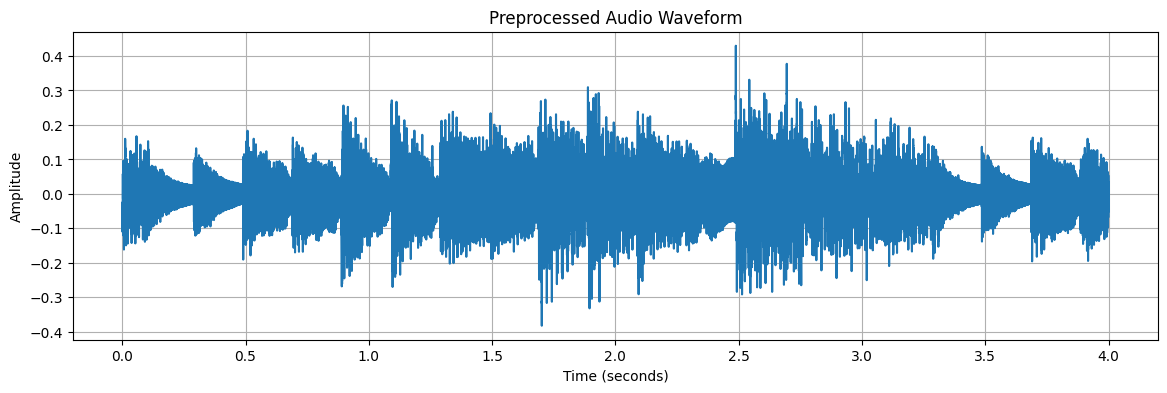

In [5]:
time_axis = np.arange(len(audio)) / 16000

plt.figure(figsize=(14, 4))

plt.plot(time_axis, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Preprocessed Audio Waveform")

plt.grid()
plt.show()